# 04 - Modeling: Predicting Credit Card Default

**Input:** `../data/cleaned.csv` (30,000 customers, encoded and scaled)

**Model:** Logistic Regression

**Workflow:**
1. Load and split into train / test
2. Baseline
3. Train Logistic Regression
4. Evaluate: accuracy, precision, recall, ROC-AUC, confusion matrix, ROC curve
5. Effect of class imbalance (balanced weights)
6. Risk tiers: low / medium / high, with the actual default rate per tier
7. Which features drive the prediction
8. Save results for the dashboard

## Step 1: Load and Split

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report)

df = pd.read_csv("../data/cleaned.csv")
print("Shape:", df.shape)

Shape: (30000, 33)


In [2]:
# X = features, y = target. ID is not a feature, it only identifies the customer
X = df.drop(columns=["ID", "default"])
y = df["default"]

# 80% train, 20% test, same default share in both (stratify), same split every run (random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Features:", X.shape[1])
print("Train:", X_train.shape, "| default %:", round(y_train.mean() * 100, 2))
print("Test: ", X_test.shape, "| default %:", round(y_test.mean() * 100, 2))

Features: 31
Train: (24000, 31) | default %: 22.12
Test:  (6000, 31) | default %: 22.12


## Step 2: Baseline

If we always predict "no default", we are right for the ~78% of customers who do not default, but we catch **no** defaulters. The model has to beat this.

In [3]:
baseline_pred = np.zeros(len(y_test))

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline recall:  ", recall_score(y_test, baseline_pred))

Baseline accuracy: 0.7788
Baseline recall:   0.0


## Step 3: Train Logistic Regression

We use the plain model (no class weights) as the main model. Its predicted probabilities stay **honest**: a predicted 30% means about 30% of such customers really default. We need that for the risk tiers in Step 6.

In [4]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

# predicted class (threshold 0.5) and predicted probability of default
y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]

## Step 4: Evaluate

- **Accuracy:** share of all predictions that are correct
- **Precision:** of the customers we flagged as defaulters, how many really defaulted
- **Recall:** of the real defaulters, how many we flagged
- **ROC-AUC:** 0.5 = random guessing, 1.0 = perfect ranking

In [5]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred, digits=3))

Accuracy : 0.8147
Precision: 0.6516
Recall   : 0.3482
ROC-AUC  : 0.7582

              precision    recall  f1-score   support

           0      0.837     0.947     0.888      4673
           1      0.652     0.348     0.454      1327

    accuracy                          0.815      6000
   macro avg      0.744     0.648     0.671      6000
weighted avg      0.796     0.815     0.792      6000



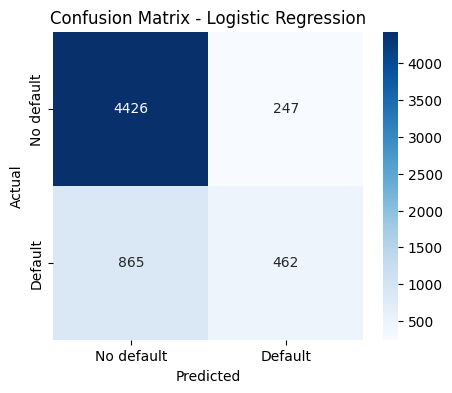

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No default", "Default"], yticklabels=["No default", "Default"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

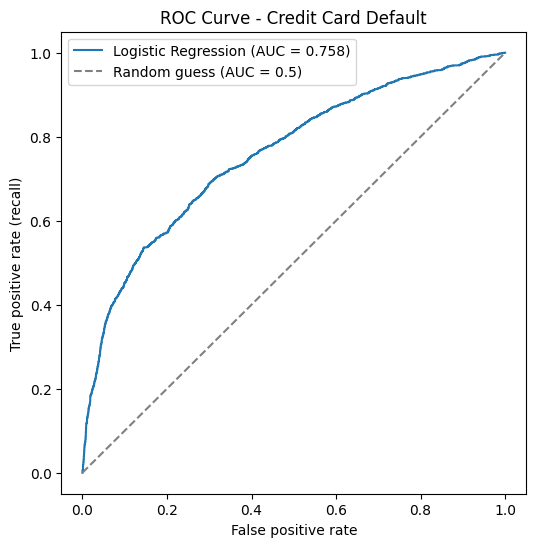

In [7]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guess (AUC = 0.5)")
plt.title("ROC Curve - Credit Card Default")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.show()

**What we see:**
- **Accuracy 0.815** beats the baseline (0.779), and **ROC-AUC 0.758** shows the model ranks risky customers well above safe ones.
- **Precision 0.652:** about 2 in 3 customers flagged as defaulters really default.
- **Recall 0.348:** the model catches only about 1 in 3 real defaulters at the 0.5 threshold. This is the weak point, because the rarer class gets less attention.

## Step 5: Effect of Class Imbalance

To catch more defaulters we can train the same model with `class_weight="balanced"`. In the training set, the rare class (default) gets weight 2.26 and the common class 0.64, so a missed defaulter counts about 3.5 times as much as a false alarm. We compare the two models here; the risk tiers still use the plain model because its probabilities are honest.

In [8]:
balanced_model = LogisticRegression(max_iter=1000, class_weight="balanced")
balanced_model.fit(X_train, y_train)

bal_pred = balanced_model.predict(X_test)
bal_prob = balanced_model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "model": ["Logistic Regression", "Logistic Regression (balanced)"],
    "accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, bal_pred)],
    "precision": [precision_score(y_test, y_pred), precision_score(y_test, bal_pred)],
    "recall": [recall_score(y_test, y_pred), recall_score(y_test, bal_pred)],
    "roc_auc": [roc_auc_score(y_test, y_prob), roc_auc_score(y_test, bal_prob)],
})
comparison.round(4)

,model,accuracy,precision,recall,roc_auc
0,Logistic Regression,0.8147,0.6516,0.3482,0.7582
1,Logistic Regression (balanced),0.7490,0.4482,0.5840,0.7607


**What we see:** balanced weights raise recall from 0.348 to 0.584 (many more defaulters caught) but lower precision from 0.652 to 0.448 (more false alarms). ROC-AUC stays almost the same (0.758 vs 0.761), because the ranking of customers barely changes; only the cut-off moves. Which one a bank prefers depends on whether a missed defaulter or a false alarm costs more.

## Step 6: Risk Tiers

We group the **test customers** by their predicted probability of default:

| Tier | Predicted probability |
|------|----------------------|
| Low | below 0.30 |
| Medium | 0.30 to 0.60 |
| High | above 0.60 |

Then we check the **actual** default rate in each tier. If the model is useful, the rate should rise clearly from Low to High.

In [9]:
tiers = pd.DataFrame({"probability": y_prob, "actual_default": y_test.values})

# pd.cut puts each probability into a tier; include_lowest=True keeps a probability of exactly 0 in Low
tiers["risk_tier"] = pd.cut(tiers["probability"], bins=[0, 0.3, 0.6, 1.0],
                            labels=["Low", "Medium", "High"], include_lowest=True)

tier_summary = tiers.groupby("risk_tier", observed=True).agg(
    customers=("actual_default", "count"),
    defaulters=("actual_default", "sum"),
    avg_predicted_prob=("probability", "mean"),
)
tier_summary["actual_default_rate_pct"] = (tier_summary["defaulters"] / tier_summary["customers"] * 100).round(2)
tier_summary["share_of_customers_pct"] = (tier_summary["customers"] / len(tiers) * 100).round(2)
tier_summary["share_of_all_defaulters_pct"] = (tier_summary["defaulters"] / tier_summary["defaulters"].sum() * 100).round(2)
tier_summary["avg_predicted_prob"] = tier_summary["avg_predicted_prob"].round(3)

tier_summary

,customers,defaulters,avg_predicted_prob,actual_default_rate_pct,share_of_customers_pct,share_of_all_defaulters_pct
risk_tier,,,,,,
Low,4612,617,0.130,13.38,76.87,46.5
Medium,972,426,0.442,43.83,16.20,32.1
High,416,284,0.717,68.27,6.93,21.4


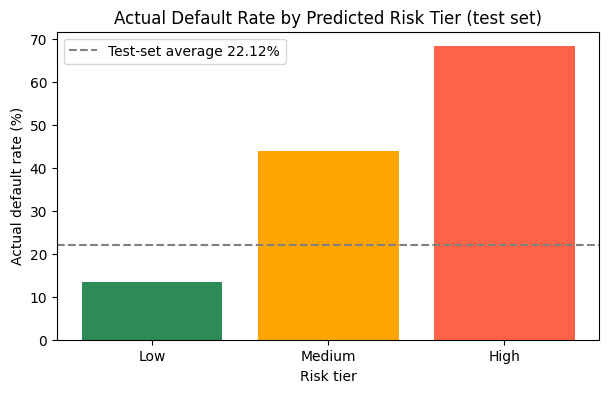

In [10]:
plt.figure(figsize=(7, 4))
plt.bar(tier_summary.index.astype(str), tier_summary["actual_default_rate_pct"], color=["seagreen", "orange", "tomato"])
plt.axhline(y_test.mean() * 100, color="grey", linestyle="--", label=f"Test-set average {y_test.mean() * 100:.2f}%")
plt.title("Actual Default Rate by Predicted Risk Tier (test set)")
plt.xlabel("Risk tier")
plt.ylabel("Actual default rate (%)")
plt.legend()
plt.show()

**What we see:**
- The actual default rate rises sharply from tier to tier: **Low 13.38% -> Medium 43.83% -> High 68.27%**.
- The average predicted probability in each tier is close to the actual rate, so the probabilities can be trusted.
- The High tier holds only 6.93% of customers but 21.4% of all defaulters. A bank could focus its collection effort there first.

## Step 7: Which Features Drive the Prediction

All numeric features are scaled, so coefficient size shows importance. **Positive = raises** default risk, **negative = lowers** it.

In [11]:
coef = pd.DataFrame({"feature": X.columns, "coefficient": log_model.coef_[0]})
coef["abs_coef"] = coef["coefficient"].abs()

top_coef = coef.sort_values("abs_coef", ascending=False).head(10)
top_coef[["feature", "coefficient"]].round(3)

,feature,coefficient
27,EDUCATION_others,-1.038
24,months_delayed,0.694
3,PAY_1,0.375
25,max_delay,0.274
4,PAY_2,-0.213
13,BILL_AMT5,-0.185
30,MARRIAGE_single,-0.148
21,credit_utilization,0.134
15,PAY_AMT1,-0.132
1,is_female,-0.125


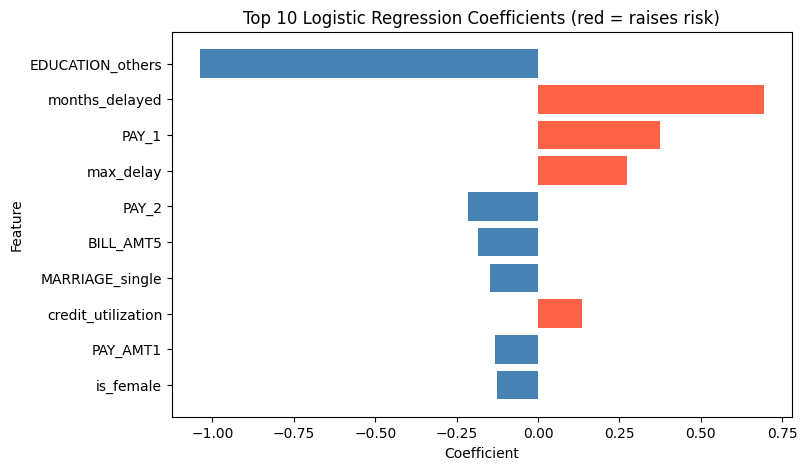

In [12]:
plt.figure(figsize=(8, 5))
colors = ["tomato" if c > 0 else "steelblue" for c in top_coef["coefficient"]]
plt.barh(top_coef["feature"], top_coef["coefficient"], color=colors)
plt.gca().invert_yaxis()
plt.title("Top 10 Logistic Regression Coefficients (red = raises risk)")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

**What we see:**
- **Payment delay features dominate:** `months_delayed` (+0.694), `PAY_1` (+0.375) and `max_delay` (+0.274) raise risk the most, matching the EDA.
- `credit_utilization` (+0.134) raises risk; a bigger September payment (`PAY_AMT1`, -0.132) lowers it.
- `EDUCATION_others` (-1.038) has the largest coefficient, because this small group (468 customers) defaults only 7.05% of the time (see EDA).
- `PAY_2` is **negative** (-0.213) even though being late in August is clearly risky. The delay features are strongly correlated with each other (up to 0.94), so the model splits their effect between them. Coefficients of correlated features should not be read one by one.

## Step 8: Save Results for the Dashboard

In [13]:
# 1. metrics of both model versions
comparison.round(4).to_csv("../data/model_metrics.csv", index=False)

# 2. tier summary (test set)
tier_summary.reset_index().to_csv("../data/risk_tier_summary.csv", index=False)

# 3. score EVERY customer with the plain model so Power BI can show a tier per customer
#    'split' tells which customers the model saw during training (train) and which it did not (test)
scores = pd.DataFrame({
    "ID": df["ID"],
    "default_probability": log_model.predict_proba(X)[:, 1].round(4),
    "actual_default": y,
})
scores["risk_tier"] = pd.cut(scores["default_probability"], bins=[0, 0.3, 0.6, 1.0],
                             labels=["Low", "Medium", "High"], include_lowest=True)
scores["split"] = "train"
scores.loc[X_test.index, "split"] = "test"
scores.to_csv("../data/customer_scores.csv", index=False)

# 4. coefficients
coef[["feature", "coefficient"]].round(4).to_csv("../data/model_coefficients.csv", index=False)

print(scores["split"].value_counts())
print("Saved model_metrics.csv, risk_tier_summary.csv, customer_scores.csv, model_coefficients.csv")

split
train    24000
test      6000
Name: count, dtype: int64
Saved model_metrics.csv, risk_tier_summary.csv, customer_scores.csv, model_coefficients.csv
